# 02. IEEE-CIS: EDA, проверка утечки и LightGBM baseline

**Задача №9 (P2).** Пункт кейса по исследованию IEEE-CIS и построению baseline-модели.

**Что делаем:**
1. Загружаем исходные `train_transaction.csv` и `train_identity.csv`, объединяем их по `TransactionID`.
2. Проводим EDA: баланс классов, пропуски, суммы операций, признаки устройства и identity.
3. Разделяем данные хронологически на train / validation / test по `TransactionDT`.
4. Строим признаки новизны устройства и карты только по предыдущим операциям.
5. Обучаем LightGBM с нуля, выбираем порог на validation и проверяем его на test.
6. Считаем метрики по формулам кейса, оцениваем сумму обнаруженных мошеннических операций и разбираем TP/FP с помощью SHAP.

**Данные:** Kaggle → Add Input → `IEEE-CIS Fraud Detection`. Для этого эксперимента используются исходные размеченные файлы `train_transaction.csv` и `train_identity.csv`.

## Общее допущение

Для проектируемой антифрод-системы принимаем допущение из кейса, часть данных о клиенте может поступать с задержкой до 24 часов. Поэтому признаки и процессы разделяются на два контура:

- **Онлайн-контур:** параметры текущей операции и сигналы, доступные непосредственно в момент её совершения.
- **Профиль клиента с задержкой:** статистики по предыдущим операциям, которые обновляются после поступления данных, в том числе с задержкой до 24 часов.

Для операции в момент времени `t` допустимо использовать только информацию, которая уже была доступна к этому моменту. Текущая операция и будущие события не должны попадать в исторические агрегаты. В методических функциях команды это соответствует `lag=0` для онлайн-истории и `lag=86400` для профиля с задержкой до суток.

IEEE-CIS используется здесь как открытый экспериментальный набор данных для проверки методики. Он не является внутренней статистикой ВТБ, не подтверждает качество модели на российских переводах и не позволяет напрямую оценить эффект внедрения в банке. `TransactionAmt` сохраняется в исходных единицах датасета: без подтверждённой конвертации эту сумму нельзя называть рублями.

ML-скоринг рассматривается как дополнительный инструмент. Он не заменяет обязательные проверки и действия, предусмотренные 161-ФЗ и применимыми требованиями Банка России. Окончательная реакция системы должна учитывать результат обязательных проверок, риск операции и сценарий взаимодействия с клиентом.

## Общие определения и формулы

Для единообразной оценки используем следующие определения:

- `TP` — мошеннические операции, которые модель отметила;
- `FP` — легальные операции, по которым модель выдала ложный сигнал;
- `FN` — мошеннические операции, которые модель пропустила;
- `TN` — легальные операции, которые модель не отметила.

Метрики по формулам кейса:

- **Точность выявления (Precision)** = `TP / (TP + FP)`.
- **Доля ложных сигналов** = `FP / (TP + FP)`.
- **FPR** — доля ложных сигналов среди всех легальных операций = `FP / (FP + TN)`.
- **Полнота обнаружения (Recall)** = `TP / (TP + FN)`.

Дополнительно считаем полноту по сумме, какую долю общей суммы мошеннических операций составляют правильно выявленные операции. Это экспериментальная оценка суммы операций, а не подтверждённый фактический предотвращённый ущерб банка.

**Важно** ложный сигнал `FP` не равен автоматически ошибочной блокировке. В архитектуре может быть несколько уровней реакции: пропуск, предупреждение/подтверждение, дополнительная проверка или ограничение в предусмотренных законом случаях. Поэтому количество FP, количество ошибочно ограниченных операций и стоимость клиентского трения — разные показатели.

Итоговые таблицы и файлы сохраняются в `/kaggle/working`.

Ноутбук полностью пересчитывает результат по исходным данным. Он не читает старые файлы предсказаний и не использует значения метрик из предыдущих запусков.

### Общие функции и принципы расчёта

Внутри ноутбука реализованы необходимые функции расчёта: временное разделение, построение исторических признаков без использования будущих событий, выбор порога по validation, расчёт метрик и экономическая оценка при заданных допущениях.

Подход соответствует общим правилам командного модуля `antifraud_utils.py`: случайное перемешивание для временных данных не используется; метрики считаются из `TP`, `FP`, `FN`, `TN`; ложные сигналы отделяются от ошибочных ограничений; экономический расчёт не выполняется без согласованной стоимости ложного сигнала.

In [1]:
import importlib.util, subprocess, sys, os, glob, warnings
for package in ["lightgbm", "shap"]:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, confusion_matrix

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

SEED = 42
TARGET_FPR = 0.01          # целевой FPR на validation
TRAIN_FRAC = 0.60
VALID_FRAC = 0.20
OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "./output"
os.makedirs(OUT_DIR, exist_ok=True)
print("LightGBM:", lgb.__version__, "| SHAP:", shap.__version__)

LightGBM: 4.6.0 | SHAP: 0.52.0


## 1. Загрузка исходных данных

На первом этапе автоматически находим исходные файлы в подключённых Kaggle-данных. Используем только два файла размеченной части соревнования: транзакционную таблицу и таблицу identity. Никакие ранее рассчитанные CSV с предсказаниями или метриками не загружаются.

Транзакционная таблица содержит сведения об операции и целевую метку `isFraud`. Таблица identity содержит дополнительные сведения об устройстве и цифровой идентичности. На следующем этапе эти данные будут связаны по идентификатору операции.


Сначала проверяем, что оба файла действительно найдены в подключённом датасете. Если файл отсутствует, выполнение останавливается с понятной подсказкой. После загрузки выводим размеры таблиц, это позволяет убедиться, что Kaggle подключил нужный набор данных, а не пустую или другую папку.


In [2]:
def locate_file(filename, root="/kaggle/input"):
    matches = glob.glob(os.path.join(root, "**", filename), recursive=True)
    if not matches:
        raise FileNotFoundError(
            f"Не найден {filename}. В Kaggle нажми Add Input и подключи IEEE-CIS Fraud Detection."
        )
    return matches[0]

train_transaction_path = locate_file("train_transaction.csv")
train_identity_path = locate_file("train_identity.csv")

train_transaction = pd.read_csv(train_transaction_path)
train_identity = pd.read_csv(train_identity_path)

print("train_transaction:", train_transaction.shape)
print("train_identity:", train_identity.shape)
print("Transaction file:", train_transaction_path)
print("Identity file:", train_identity_path)

train_transaction: (590540, 394)
train_identity: (144233, 41)
Transaction file: /kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv
Identity file: /kaggle/input/competitions/ieee-fraud-detection/train_identity.csv


## 2. Объединение transaction и identity

### Что проверяем и зачем

Сначала объединяем таблицы по `TransactionID`. Связь выполняется как `left join`, каждая транзакция остаётся в выборке, даже если для неё нет записи в identity. Это важно, поскольку отсутствие сведений об устройстве само по себе не означает, что операцию нужно удалить или считать мошеннической.

Далее выполняем первичный разведочный анализ (EDA):

- проверяем размер объединённой таблицы и временной диапазон;
- смотрим долю мошеннических операций и дисбаланс классов;
- оцениваем пропуски, в том числе в `DeviceType`, `DeviceInfo` и `id_*`;
- сравниваем распределения сумм легальных и мошеннических операций.

### Как интерпретировать

В антифроде мошеннические операции обычно составляют меньшую часть данных. Поэтому одной accuracy недостаточно, модель может часто угадывать легальный класс и при этом пропускать значительную часть мошенничества. Пропуски identity рассматриваем как особенность доступности данных, позже модель сможет использовать сам факт отсутствия части сведений, если он информативен.


Общий размер: (590540, 434)
Период TransactionDT: 86400 — 15811131
Доля мошенничества: 3.499%
Число мошеннических операций: 20663


,Операций
isFraud,
Легальные,569877
Мошеннические,20663


,"Пропуски, %"
id_24,99.1962
id_25,99.1310
id_07,99.1271
id_08,99.1271
id_21,99.1264
id_26,99.1257
id_22,99.1247
id_27,99.1247
id_23,99.1247
dist2,93.6284


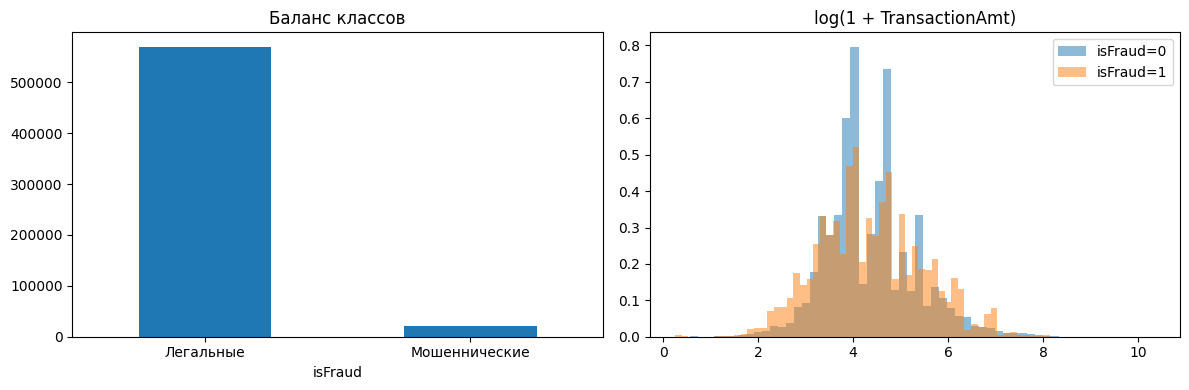

,missing_%,unique_values
id_24,99.1962,12
id_25,99.1310,341
id_08,99.1271,94
id_07,99.1271,84
id_21,99.1264,490
id_26,99.1257,95
id_22,99.1247,25
id_23,99.1247,3
id_27,99.1247,2
id_18,92.3607,18


,operations,fraud_rate
DeviceType,,
NaN,449730,0.0210
desktop,85165,0.0652
mobile,55645,0.1017


In [3]:
assert train_transaction["TransactionID"].is_unique
assert train_identity["TransactionID"].is_unique

data = train_transaction.merge(
    train_identity, on="TransactionID", how="left", validate="one_to_one"
)
del train_transaction, train_identity

print("Общий размер:", data.shape)
print("Период TransactionDT:", data["TransactionDT"].min(), "—", data["TransactionDT"].max())
print("Доля мошенничества:", f"{data['isFraud'].mean():.3%}")
print("Число мошеннических операций:", int(data["isFraud"].sum()))

display(data["isFraud"].value_counts().rename(index={0:"Легальные",1:"Мошеннические"}).to_frame("Операций"))
display((data.isna().mean()*100).sort_values(ascending=False).head(25).to_frame("Пропуски, %"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
data["isFraud"].value_counts().sort_index().plot(kind="bar", ax=ax[0], title="Баланс классов")
ax[0].set_xticklabels(["Легальные", "Мошеннические"], rotation=0)
for label, part in data.groupby("isFraud"):
    ax[1].hist(np.log1p(part["TransactionAmt"].clip(lower=0)), bins=60,
               alpha=.5, density=True, label=f"isFraud={label}")
ax[1].set_title("log(1 + TransactionAmt)")
ax[1].legend()
plt.tight_layout()
plt.show()

device_cols = [c for c in ["DeviceType", "DeviceInfo"] if c in data.columns]
id_cols = [c for c in data.columns if c.startswith("id_")]
eda_cols = device_cols + id_cols
if eda_cols:
    display(pd.DataFrame({
        "missing_%": data[eda_cols].isna().mean()*100,
        "unique_values": data[eda_cols].nunique(dropna=True)
    }).sort_values("missing_%", ascending=False))
if "DeviceType" in data:
    display(data.groupby("DeviceType", dropna=False)["isFraud"]
            .agg(operations="size", fraud_rate="mean")
            .sort_values("operations", ascending=False))

## 3. Временной split по TransactionDT
Сортировка по TransactionDT. Последняя часть данных остаётся test она не участвует в обучении или выборе порога.

### Почему разделяем данные по времени

В реальном банке модель обучается на уже произошедших операциях, а затем принимает решения по новым. Случайное перемешивание может поместить более поздние события в обучение, а более ранние — в тест, из-за чего оценка будет слишком оптимистичной.

Поэтому сортируем операции по `TransactionDT` и делим их хронологически: первые 60% — обучение, следующие 20% — валидация, последние 20% — тест. Обучающая часть используется для подбора параметров модели, validation — для ранней остановки и выбора порога, test — только для итоговой независимой оценки.

Границы определяются по квантилям времени. Из-за одинаковых временных отметок фактические доли частей могут немного отличаться от 60/20/20.

В соответствии с общим подходом команды используем временное разделение, ранние события идут в обучение, следующий временной отрезок — валидацию, самый поздний — тест. В отличие от случайного split, такая схема не подмешивает будущие операции в прошлое и ближе к реальному сценарию эксплуатации антифрод-модели.

Validation используется для выбора параметров и порога. Test сохраняется для финальной проверки и не должен использоваться для повторной подстройки модели.

In [4]:
data = data.sort_values(["TransactionDT", "TransactionID"], kind="mergesort").reset_index(drop=True)
q_train = data["TransactionDT"].quantile(TRAIN_FRAC)
q_valid = data["TransactionDT"].quantile(TRAIN_FRAC + VALID_FRAC)

train_df = data[data["TransactionDT"] <= q_train].copy()
valid_df = data[(data["TransactionDT"] > q_train) & (data["TransactionDT"] <= q_valid)].copy()
test_df = data[data["TransactionDT"] > q_valid].copy()

for name, part in [("train", train_df), ("validation", valid_df), ("test", test_df)]:
    print(f"{name:10s} n={len(part):,}; fraud={int(part.isFraud.sum()):,}; "
          f"fraud_rate={part.isFraud.mean():.3%}; "
          f"DT={part.TransactionDT.min():,.0f}..{part.TransactionDT.max():,.0f}")

assert min(len(train_df), len(valid_df), len(test_df)) > 0

train      n=354,324; fraud=11,988; fraud_rate=3.383%; DT=86,400..8,745,772
validation n=118,108; fraud=4,611; fraud_rate=3.904%; DT=8,745,798..12,192,842
test       n=118,108; fraud=4,064; fraud_rate=3.441%; DT=12,192,900..15,811,131


## 4. Новизна устройства и карты
Для каждой временной части признаки строятся только по более ранним событиям. Метка `isFraud` в построении признаков не используется.

### Логика построения признаков

Для антифрод-системы важно не только само устройство или карточный набор параметров, но и то, встречались ли они раньше. Впервые замеченное устройство или необычный карточный профиль могут быть дополнительным сигналом риска.

Для каждой операции рассчитываем:

- `device_new` — встречается ли устройство впервые в доступной истории;
- `device_prev_count` — число более ранних операций с этим устройством;
- `card_new` — встречается ли карточный ключ впервые;
- `card_prev_count` — число более ранних операций с этим карточным ключом.

Ключ устройства строится из доступных `DeviceType` и `DeviceInfo`, ключ карты — из доступных полей `card1`, `card2`, `card3`, `card5`. Если необходимые значения отсутствуют, это учитывается отдельно и не подменяется искусственным утверждением, что устройство или карта новые.

### Защита от утечки будущего

История сортируется по `TransactionDT`. Для каждой строки учитываются только более ранние события, текущая операция и будущие операции не должны влиять на её признаки. Целевая метка `isFraud` в функцию построения новизны не передаётся. Признак должен быть доступен в момент принятия решения, а не раскрывать ответ из разметки.

Новизна рассчитывается по истории событий, а не по метке `isFraud`. Для каждой операции используем только события с меньшим временем `TransactionDT`. Поэтому `device_prev_count` и `card_prev_count` описывают, сколько соответствующих появлений уже было до текущей операции.

Это упрощённые исторические признаки по устройству и карте. Они не являются полноценным клиентским профилем с задержкой 24 часа, для такого профиля в отдельном контуре нужно рассчитывать агрегаты с соответствующим лагом и по доступному в банке идентификатору клиента.

In [5]:
NOVELTY_COLS = ["device_new", "device_prev_count", "card_new", "card_prev_count"]

def make_past_novelty(history, target_ids):
    cols = ["TransactionID", "TransactionDT"] + [
        c for c in ["DeviceType", "DeviceInfo", "card1", "card2", "card3", "card5"]
        if c in history.columns
    ]
    h = history[cols].sort_values(["TransactionDT", "TransactionID"], kind="mergesort").copy()

    dev_cols = [c for c in ["DeviceType", "DeviceInfo"] if c in h]
    if dev_cols:
        has_dev = h[dev_cols].notna().any(axis=1)
        dev_key = h[dev_cols].astype("string").fillna("<NA>").agg("|".join, axis=1)
        h["_dev"] = dev_key.where(has_dev, pd.NA)
    else:
        has_dev = pd.Series(False, index=h.index)
        h["_dev"] = pd.NA

    card_cols = [c for c in ["card1", "card2", "card3", "card5"] if c in h]
    if card_cols:
        has_card = h["card1"].notna() if "card1" in h else h[card_cols].notna().any(axis=1)
        card_key = h[card_cols].astype("string").fillna("<NA>").agg("|".join, axis=1)
        h["_card"] = card_key.where(has_card, pd.NA)
    else:
        has_card = pd.Series(False, index=h.index)
        h["_card"] = pd.NA

    dcount = h.groupby("_dev", dropna=True, sort=False).cumcount()
    ccount = h.groupby("_card", dropna=True, sort=False).cumcount()

    h["device_new"] = ((dcount == 0) & has_dev).astype("int8")
    h["device_prev_count"] = np.where(has_dev, dcount, -1).astype("int32")
    h["card_new"] = ((ccount == 0) & has_card).astype("int8")
    h["card_prev_count"] = np.where(has_card, ccount, -1).astype("int32")

    return h.loc[h.TransactionID.isin(target_ids), ["TransactionID"] + NOVELTY_COLS].copy()

# Train history -> train rows
nov_train = make_past_novelty(train_df, train_df.TransactionID)
train_df = train_df.merge(nov_train, on="TransactionID", validate="one_to_one")

# Train + validation history -> validation rows
hist_train_valid = pd.concat([
    train_df.drop(columns=NOVELTY_COLS), valid_df
], ignore_index=True, sort=False)
nov_valid = make_past_novelty(hist_train_valid, valid_df.TransactionID)
valid_df = valid_df.merge(nov_valid, on="TransactionID", validate="one_to_one")

# Train + validation + test history -> test rows
hist_before_test = pd.concat([
    train_df.drop(columns=NOVELTY_COLS),
    valid_df.drop(columns=NOVELTY_COLS),
    test_df
], ignore_index=True, sort=False)
nov_test = make_past_novelty(hist_before_test, test_df.TransactionID)
test_df = test_df.merge(nov_test, on="TransactionID", validate="one_to_one")

print("Доля новых устройств:")
print("train", train_df.device_new.mean(), "validation", valid_df.device_new.mean(), "test", test_df.device_new.mean())
print("Доля новых карт:")
print("train", train_df.card_new.mean(), "validation", valid_df.card_new.mean(), "test", test_df.card_new.mean())

Доля новых устройств:
train 0.004253169415563157 validation 0.0021421072238967725 test 0.0015409625088901684
Доля новых карт:
train 0.03573000982151929 validation 0.009220374572425237 test 0.009279642361228706


## 5. Подготовка признаков для модели
`TransactionID`, `isFraud` и `TransactionDT` исключаются из модели. Категории validation/test приводятся к категориям train.

Перед обучением отделяем целевую переменную от входных данных. `isFraud` — правильный ответ, который модель должна научиться предсказывать; поэтому он не может быть признаком. `TransactionID` является техническим идентификатором, а `TransactionDT` используется для временного разделения, но исключается из набора признаков, чтобы модель не запоминала временную позицию операции как произвольный числовой идентификатор.

Категориальные поля приводим к согласованному набору категорий, сформированному по train. Новые категории, встретившиеся только в validation или test, не должны менять пространство признаков модели. Пропуски категориальных значений обозначаются отдельной категорией.


In [6]:
DROP_COLS = ["TransactionID", "isFraud", "TransactionDT"]
FEATURES = [c for c in train_df.columns if c not in DROP_COLS]

X_train = train_df[FEATURES].copy()
y_train = train_df["isFraud"].astype("int8")
X_valid = valid_df[FEATURES].copy()
y_valid = valid_df["isFraud"].astype("int8")
X_test = test_df[FEATURES].copy()
y_test = test_df["isFraud"].astype("int8")

cat_cols = X_train.select_dtypes(include=["object", "category", "string"]).columns.tolist()
for col in cat_cols:
    X_train[col] = X_train[col].astype("string").fillna("<MISSING>").astype("category")
    cats = X_train[col].cat.categories
    X_valid[col] = pd.Categorical(X_valid[col].astype("string").fillna("<MISSING>"), categories=cats)
    X_test[col] = pd.Categorical(X_test[col].astype("string").fillna("<MISSING>"), categories=cats)

print("Всего признаков:", len(FEATURES))
print("Категориальных:", len(cat_cols))

Всего признаков: 435
Категориальных: 31


## 6. Обучение LightGBM

### Почему LightGBM

LightGBM — градиентный бустинг на деревьях решений. Он подходит для табличных данных, умеет учитывать нелинейные зависимости и взаимодействия между признаками, а также работает с большим количеством числовых и категориальных переменных.

Обучение выполняется на train. Validation используется для контроля качества по AUC и ранней остановки, если качество перестаёт улучшаться, обучение прекращается, чтобы не продолжать подгонку под обучающую выборку. Test на этом этапе не используется.

В результате получаем модель, которая выдаёт для каждой операции оценку риска мошенничества. Эта оценка не является окончательным решением о блокировке, ведь далее выбирается порог, а реакция банка должна учитывать обязательные правила и сценарий операции.


In [7]:
params = {
    "objective": "binary",
    "metric": "auc",
    "learning_rate": 0.03,
    "num_leaves": 63,
    "max_depth": -1,
    "min_child_samples": 100,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l1": 0.0,
    "lambda_l2": 1.0,
    "verbosity": -1,
    "seed": SEED,
    "feature_pre_filter": False,
    "num_threads": -1,
}

dtrain = lgb.Dataset(X_train, label=y_train, categorical_feature=cat_cols, free_raw_data=False)
dvalid = lgb.Dataset(X_valid, label=y_valid, categorical_feature=cat_cols,
                      reference=dtrain, free_raw_data=False)

model = lgb.train(
    params,
    dtrain,
    num_boost_round=3000,
    valid_sets=[dvalid],
    valid_names=["validation"],
    callbacks=[lgb.early_stopping(150), lgb.log_evaluation(100)]
)

print("Лучшая итерация:", model.best_iteration)

Training until validation scores don't improve for 150 rounds
[100]	validation's auc: 0.906127
[200]	validation's auc: 0.920151
[300]	validation's auc: 0.923359
[400]	validation's auc: 0.924714
[500]	validation's auc: 0.925345
[600]	validation's auc: 0.925501
[700]	validation's auc: 0.926164
[800]	validation's auc: 0.925766
Early stopping, best iteration is:
[703]	validation's auc: 0.92626
Лучшая итерация: 703


## 7. Выбор порога на validation
Порог выбирается исключительно на validation, затем без изменений применяется к test.

### Зачем нужен порог

Модель возвращает непрерывный score. Чтобы получить бинарный сигнал, нужно выбрать порог, если score не ниже порога, операция отмечается как подозрительная.

В качестве ориентира задаём целевой FPR не выше 1% на validation. FPR — доля легальных операций, ошибочно отмеченных моделью, среди всех фактически легальных операций. Порог рассчитывается только по validation и затем фиксируется. На test он применяется без повторной настройки.

Важно целевой FPR на validation не гарантирует такой же FPR на test. Если на тестовом периоде он окажется выше 1%, это нужно показать как результат проверки переноса во времени, а не менять порог задним числом.


In [8]:
valid_score = model.predict(X_valid, num_iteration=model.best_iteration)
test_score = model.predict(X_test, num_iteration=model.best_iteration)

def threshold_for_fpr(y_true, scores, target_fpr=0.01):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    legit_scores = np.sort(scores[y_true == 0])[::-1]
    if len(legit_scores) == 0:
        raise ValueError("В validation нет легальных операций.")
    k = int(np.floor(target_fpr * len(legit_scores)))
    # строго выше граничного легального score, чтобы не превысить target FPR
    return float(np.nextafter(legit_scores[min(k, len(legit_scores)-1)], np.inf))

threshold = threshold_for_fpr(y_valid, valid_score, TARGET_FPR)
print(f"Порог, выбранный на validation: {threshold:.12f}")

def calculate_metrics(y_true, scores, thr, amount=None):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    pred = scores >= thr
    tp = int(((y_true == 1) & pred).sum())
    fp = int(((y_true == 0) & pred).sum())
    fn = int(((y_true == 1) & ~pred).sum())
    tn = int(((y_true == 0) & ~pred).sum())
    out = {
        "N": len(y_true), "Fraud": int(y_true.sum()),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Precision": tp/(tp+fp) if tp+fp else np.nan,
        "Recall": tp/(tp+fn) if tp+fn else np.nan,
        "FPR": fp/(fp+tn) if fp+tn else np.nan,
        "False_signal_share": fp/(tp+fp) if tp+fp else np.nan,
        "ROC_AUC": roc_auc_score(y_true, scores),
        "PR_AUC": average_precision_score(y_true, scores),
        "Threshold": float(thr)
    }
    if amount is not None:
        amount = np.asarray(amount, dtype=float)
        fraud_amount = amount[y_true == 1].sum()
        caught_amount = amount[(y_true == 1) & pred].sum()
        out.update({
            "Fraud_amount_units": float(fraud_amount),
            "Prevented_amount_units_assuming_full_stop": float(caught_amount),
            "Missed_fraud_amount_units": float(fraud_amount-caught_amount),
            "Amount_recall": float(caught_amount/fraud_amount) if fraud_amount else np.nan
        })
    return out

valid_metrics = calculate_metrics(y_valid, valid_score, threshold, valid_df["TransactionAmt"])
test_metrics = calculate_metrics(y_test, test_score, threshold, test_df["TransactionAmt"])

print("\\nVALIDATION METRICS")
display(pd.DataFrame([valid_metrics]).T.rename(columns={0:"Validation"}))
print("\\nTEST METRICS — ЭТО ОСНОВНАЯ СТРОКА ДЛЯ ОЦЕНКИ")
display(pd.DataFrame([test_metrics]).T.rename(columns={0:"Test"}))

Порог, выбранный на validation: 0.180435496598
\nVALIDATION METRICS


,Validation
N,"118,108.0000"
Fraud,"4,611.0000"
TP,"2,420.0000"
FP,"1,134.0000"
FN,"2,191.0000"
TN,"112,363.0000"
Precision,0.6809
Recall,0.5248
FPR,0.0100
False_signal_share,0.3191


\nTEST METRICS — ЭТО ОСНОВНАЯ СТРОКА ДЛЯ ОЦЕНКИ


,Test
N,"118,108.0000"
Fraud,"4,064.0000"
TP,"1,779.0000"
FP,"1,461.0000"
FN,"2,285.0000"
TN,"112,583.0000"
Precision,0.5491
Recall,0.4377
FPR,0.0128
False_signal_share,0.4509


## 8. Цена ошибки и экономические допущения
Формула из экономического примера: `cost = missed_fraud_amount × loss_share + FP × cost_fp`. Для IEEE-CIS валюта `TransactionAmt` не подтверждена как рубли, поэтому обе величины должны быть в одной и той же единице. Ниже код считает кривую только после задания `COST_FP` в единицах `TransactionAmt`, по умолчанию не подставляет выдуманное значение.

### Экономический смысл формулы

Ошибки модели имеют разную цену. Пропуск мошеннической операции может привести к потерям, а ложный сигнал по законной операции — к дополнительной проверке, задержке перевода, обращению в контакт-центр или отказу клиента от операции.

Используем общую формулу:
`cost = missed_fraud_amount × loss_share + FP × cost_fp`.

`missed_fraud_amount` — сумма мошеннических операций, которые модель не отметила; `loss_share` — доля этой суммы, рассматриваемая как потери; `FP` — число ложных сигналов; `cost_fp` — стоимость одного ложного сигнала.

Для IEEE-CIS нельзя автоматически подставлять рублёвую стоимость ошибки из расчётов по ВТБ: единицы `TransactionAmt` не подтверждены как рубли. Поэтому `COST_FP` по умолчанию оставлен незаданным. Если команда согласует стоимость в тех же единицах, её можно внести в настройку и получить кривую стоимости. Без такого допущения корректнее не выдавать искусственный «экономически оптимальный» порог.


В общей функции команды стоимость ошибки задаётся формулой `missed_fraud_amount × loss_share + FP × cost_fp`. Здесь `loss_share` задаёт долю суммы пропущенного мошенничества, учитываемую как потери, а `cost_fp` — согласованную стоимость одного ложного сигнала в сопоставимых единицах.

Для IEEE-CIS единицы `TransactionAmt` не подтверждены как рубли, а стоимость FP из внутренних процессов ВТБ в этих данных отсутствует. Поэтому экономическую стоимость нельзя достоверно оптимизировать без дополнительных исходных параметров. Если параметр стоимости FP не задан, ноутбук должен явно сообщить, что полная стоимость не рассчитана, а не подставлять выдуманное значение.


In [9]:
def cost_curve(y_true, scores, amount, cost_fp, loss_share=1.0):
    y = np.asarray(y_true).astype(int)
    s = np.asarray(scores, dtype=float)
    a = np.asarray(amount, dtype=float)
    order = np.argsort(-s, kind="mergesort")
    y, s, a = y[order], s[order], a[order]
    tp = np.cumsum(y)
    fp = np.cumsum(1-y)
    caught = np.cumsum(a*y)
    total_fraud_amount = float((a*y).sum())
    last = np.r_[s[1:] != s[:-1], True]
    idx = np.where(last)[0]
    curve = pd.DataFrame({
        "threshold": s[idx],
        "TP": tp[idx],
        "FP": fp[idx],
        "missed_amount": total_fraud_amount-caught[idx]
    })
    curve = pd.concat([
        pd.DataFrame({"threshold":[np.inf], "TP":[0], "FP":[0],
                      "missed_amount":[total_fraud_amount]}),
        curve
    ], ignore_index=True)
    curve["cost"] = curve["missed_amount"]*loss_share + curve["FP"]*cost_fp
    return curve

# Введи подтверждённую цену одного ложного сигнала в единицах TransactionAmt.
# Оставь None, если такой оценки нет. Это не рублёвое значение.
COST_FP = None
LOSS_SHARE = 1.0

if COST_FP is None:
    print("Полная цена ошибки не рассчитана: COST_FP не задан в сопоставимых единицах.")
else:
    validation_cost_curve = cost_curve(
        y_valid, valid_score, valid_df["TransactionAmt"],
        cost_fp=float(COST_FP), loss_share=LOSS_SHARE
    )
    best_cost_row = validation_cost_curve.loc[validation_cost_curve["cost"].idxmin()]
    display(validation_cost_curve.sort_values("cost").head(10))
    print("Оптимальный по заданной цене порог на validation:", best_cost_row["threshold"])

Полная цена ошибки не рассчитана: COST_FP не задан в сопоставимых единицах.


## 9. Метрики по формулам кейса

### Что показывают метрики

Матрица ошибок сопоставляет фактический класс и прогноз модели:

- **TP** — мошенническая операция правильно отмечена;
- **FP** — легальная операция ошибочно отмечена;
- **FN** — мошенническая операция пропущена;
- **TN** — легальная операция правильно оставлена без сигнала.

По формулам кейса рассчитываются:

- `Precision = TP / (TP + FP)` — какая доля всех сигналов действительно приходится на мошеннические операции;
- `Recall = TP / (TP + FN)` — какую долю мошеннических операций модель обнаружила;
- `FPR = FP / (FP + TN)` — какая доля легальных операций получила ложный сигнал;
- `Доля ложных сигналов = FP / (TP + FP)` — какая доля всех сигналов оказалась ложной.

Дополнительно выводятся ROC-AUC и PR-AUC. ROC-AUC оценивает ранжирование классов при разных порогах, а PR-AUC особенно полезна при сильном дисбалансе классов. Ни одна отдельная метрика не описывает качество полностью, поэтому рассматриваем их вместе.

**Важно для трактовки:** FP — это ложные сигналы модели, а не автоматически ошибочные блокировки. Фактическая реакция может быть мягкой, предупреждение или дополнительное подтверждение. Поэтому число FP нельзя напрямую называть числом заблокированных законных переводов.


Метрики выводятся как в абсолютных значениях (количество TP/FP/FN/TN), так и в долях. Это важно для обсуждения результата, одна только доля ложных сигналов среди всех сигналов не показывает, насколько часто система ошибается на всём потоке законных операций. Для этого отдельно смотрим FPR.

Порог на validation настраивается под целевой FPR, но фактическое значение FPR на test может оказаться выше. В отчёте показываем именно фактический test-результат, не выдавая целевое ограничение за достигнутую гарантию.


,Прогноз: легальная,Прогноз: мошенничество
Факт: легальная,112583,1461
Факт: мошенничество,2285,1779


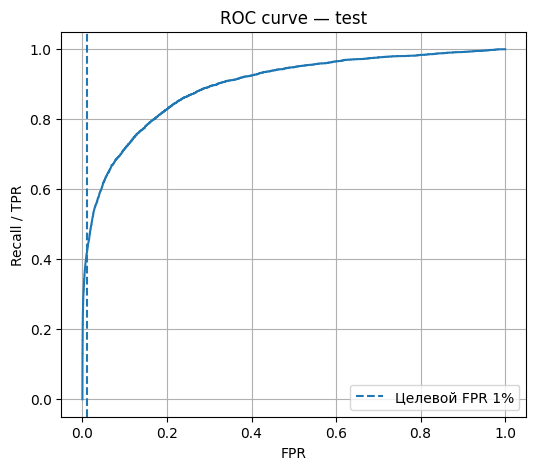

,N,Fraud,TP,FP,FN,TN,Precision,Recall,FPR,False_signal_share,ROC_AUC,PR_AUC,Threshold,Fraud_amount_units,Prevented_amount_units_assuming_full_stop,Missed_fraud_amount_units,Amount_recall
0,118108,4064,2591,6459,1473,107585,0.2863,0.6375,0.0566,0.7137,0.8969,0.5072,0.0500,"609,934.3360","373,175.3170","236,759.0190",0.6118
1,118108,4064,2156,2943,1908,111101,0.4228,0.5305,0.0258,0.5772,0.8969,0.5072,0.1000,"609,934.3360","277,008.6250","332,925.7110",0.4542
2,118108,4064,1779,1461,2285,112583,0.5491,0.4377,0.0128,0.4509,0.8969,0.5072,0.1804,"609,934.3360","210,642.1960","399,292.1400",0.3454
3,118108,4064,1731,1291,2333,112753,0.5728,0.4259,0.0113,0.4272,0.8969,0.5072,0.2000,"609,934.3360","202,650.1100","407,284.2260",0.3322
4,118108,4064,1529,716,2535,113328,0.6811,0.3762,0.0063,0.3189,0.8969,0.5072,0.3000,"609,934.3360","168,437.1120","441,497.2240",0.2762
5,118108,4064,1225,281,2839,113763,0.8134,0.3014,0.0025,0.1866,0.8969,0.5072,0.5000,"609,934.3360","115,901.4920","494,032.8440",0.1900
6,118108,4064,997,135,3067,113909,0.8807,0.2453,0.0012,0.1193,0.8969,0.5072,0.7000,"609,934.3360","87,534.1010","522,400.2350",0.1435
7,118108,4064,674,58,3390,113986,0.9208,0.1658,0.0005,0.0792,0.8969,0.5072,0.9000,"609,934.3360","61,198.3710","548,735.9650",0.1003


In [10]:
cm = confusion_matrix(y_test, (test_score >= threshold).astype(int), labels=[0,1])
display(pd.DataFrame(cm, index=["Факт: легальная","Факт: мошенничество"],
                     columns=["Прогноз: легальная","Прогноз: мошенничество"]))

fpr, tpr, roc_thresholds = roc_curve(y_test, test_score)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr)
plt.axvline(TARGET_FPR, linestyle="--", label="Целевой FPR 1%")
plt.xlabel("FPR")
plt.ylabel("Recall / TPR")
plt.title("ROC curve — test")
plt.legend()
plt.grid(True)
plt.show()

threshold_rows = []
for thr in [0.05, 0.1, threshold, 0.2, 0.3, 0.5, 0.7, 0.9]:
    threshold_rows.append(calculate_metrics(y_test, test_score, thr, test_df["TransactionAmt"]))
threshold_comparison = pd.DataFrame(threshold_rows).drop_duplicates("Threshold").sort_values("Threshold")
display(threshold_comparison)

## 10. Важность признаков модели

LightGBM позволяет оценить важность признаков по двум показателям: `gain` отражает вклад признака в улучшение качества разбиений, а `split` — сколько раз признак использовался в деревьях. Это глобальная оценка по модели, а не объяснение отдельной операции.

Высокая важность не означает причинно-следственную связь и не доказывает мошенничество. Она помогает понять, какие группы данных модель использует чаще, и определить признаки, которые стоит дополнительно проверить на устойчивость и доступность в реальном банковском процессе.


,feature,gain,split
309,V258,"112,676.9371",62
430,DeviceInfo,"49,927.6283",1664
14,C1,"49,771.1533",583
27,C14,"39,527.4768",419
3,card2,"32,465.3203",2125
26,C13,"32,014.4207",920
2,card1,"31,510.0019",2187
8,addr1,"27,950.6721",1923
345,V294,"26,238.0348",90
0,TransactionAmt,"25,430.7447",1609


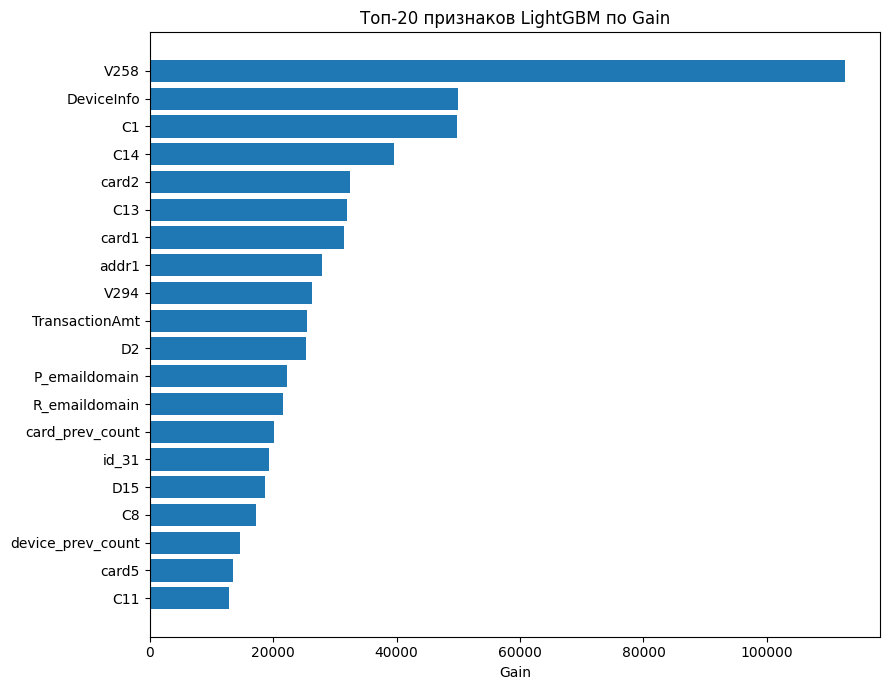

In [11]:
importance = pd.DataFrame({
    "feature": model.feature_name(),
    "gain": model.feature_importance(importance_type="gain"),
    "split": model.feature_importance(importance_type="split")
}).sort_values("gain", ascending=False)
display(importance.head(30))

top = importance.head(20).sort_values("gain")
plt.figure(figsize=(9,7))
plt.barh(top.feature, top.gain)
plt.title("Топ-20 признаков LightGBM по Gain")
plt.xlabel("Gain")
plt.tight_layout()
plt.show()

## 11. SHAP: топ-3 фактора для TP и FP
SHAP объясняет именно модель, обученную в этом запуске. Анонимизированные коды V*/C*/id_* нельзя трактовать как доказательство мошенничества.

### Что даёт SHAP

SHAP объясняет отдельный прогноз: показывает, какие признаки сдвинули оценку риска конкретной операции вверх или вниз относительно базового уровня модели. Для примеров выбираются два правильно обнаруженных мошеннических случая (TP) и один ложный сигнал (FP), если такие примеры есть в тестовой выборке.

Для каждого случая выводятся три наиболее значимых вклада. Положительный вклад повышает score модели, отрицательный — снижает. Это объяснение поведения алгоритма, а не доказательство того, что конкретное поле является причиной мошенничества.

Коды вида `C*`, `V*`, `id_*` анонимизированы в исходном наборе данных. Их нельзя переводить в понятные клиенту утверждения без подтверждённого словаря признаков. В клиентском сообщении следует объяснять ситуацию нейтрально, а оператору показывать технические факторы вместе с контекстом операции и вопросами для проверки.


Для каждого примера интерпретируем направление вклада: положительный SHAP повышает оценку риска, отрицательный — снижает. Для оператора можно показать технические факторы и контекст операции. Клиентское сообщение должно оставаться нейтральным: нельзя сообщать клиенту, что конкретный анонимизированный код `C*`, `V*` или `id_*` доказывает мошенничество.


In [12]:
test_cases = test_df[["TransactionID", "isFraud"]].copy().reset_index(drop=True)
test_cases["score"] = test_score
test_cases["prediction"] = (test_score >= threshold).astype(int)
test_cases["case"] = np.select(
    [(test_cases.isFraud==1)&(test_cases.prediction==1),
     (test_cases.isFraud==0)&(test_cases.prediction==1)],
    ["TP","FP"], default="other"
)

chosen = []
for label, n in [("TP",2), ("FP",1)]:
    chosen.extend(test_cases.loc[test_cases.case==label, "TransactionID"].head(n).tolist())

if chosen:
    id_to_pos = pd.Series(np.arange(len(test_df)), index=test_df.TransactionID)
    pos = id_to_pos.loc[chosen].to_numpy()
    X_exp = X_test.iloc[pos]
    explainer = shap.TreeExplainer(model)
    shap_raw = explainer.shap_values(X_exp, check_additivity=False)
    if isinstance(shap_raw, list):
        shap_values = np.asarray(shap_raw[1 if len(shap_raw)>1 else 0])
    else:
        shap_values = np.asarray(shap_raw)
        if shap_values.ndim == 3:
            shap_values = shap_values[:,:,1] if shap_values.shape[-1]>1 else shap_values[:,:,0]

    shap_rows = []
    for i, txid in enumerate(chosen):
        case = test_cases.loc[test_cases.TransactionID==txid].iloc[0]
        top_idx = np.argsort(np.abs(shap_values[i]))[::-1][:3]
        for rank, j in enumerate(top_idx, start=1):
            val = float(shap_values[i,j])
            shap_rows.append({
                "TransactionID": int(txid),
                "case": case.case,
                "actual_isFraud": int(case.isFraud),
                "score": float(case.score),
                "rank": rank,
                "feature": FEATURES[j],
                "SHAP": val,
                "direction": "повышает риск" if val>0 else "снижает риск"
            })
    shap_examples = pd.DataFrame(shap_rows)
    display(shap_examples)
else:
    shap_examples = pd.DataFrame()
    print("На test при выбранном пороге нет TP/FP для примеров.")

,TransactionID,case,actual_isFraud,score,rank,feature,SHAP,direction
0,3459504,TP,1,0.7098,1,C1,0.7881,повышает риск
1,3459504,TP,1,0.7098,2,V258,0.7383,повышает риск
2,3459504,TP,1,0.7098,3,DeviceInfo,-0.3620,снижает риск
3,3459510,TP,1,0.6238,1,C1,1.6751,повышает риск
4,3459510,TP,1,0.6238,2,C13,1.0581,повышает риск
5,3459510,TP,1,0.6238,3,C14,0.9695,повышает риск
6,3459708,FP,0,0.1889,1,C14,1.4049,повышает риск
7,3459708,FP,0,0.1889,2,id_30,-1.0922,снижает риск
8,3459708,FP,0,0.1889,3,R_emaildomain,0.7177,повышает риск


## 12. Сохранение результатов

В конце сохраняем артефакты текущего запуска в `/kaggle/working`: итоговые метрики validation и test, предсказания, важность признаков, сравнение порогов и SHAP-примеры. Эти файлы создаются заново после выполнения ноутбука.

In [13]:
# Метрики, рассчитанные только в этом запуске
metrics_table = pd.DataFrame([
    {"split":"validation", **valid_metrics},
    {"split":"test", **test_metrics}
])
metrics_table.to_csv(os.path.join(OUT_DIR, "metrics_ieee_cis_baseline.csv"), index=False)
importance.to_csv(os.path.join(OUT_DIR, "ieee_cis_feature_importance.csv"), index=False)
threshold_comparison.to_csv(os.path.join(OUT_DIR, "ieee_cis_threshold_comparison.csv"), index=False)
if len(shap_examples):
    shap_examples.to_csv(os.path.join(OUT_DIR, "ieee_cis_shap_examples.csv"), index=False)

predictions = pd.DataFrame({
    "TransactionID": test_df.TransactionID.to_numpy(),
    "TransactionDT": test_df.TransactionDT.to_numpy(),
    "isFraud": y_test.to_numpy(),
    "score": test_score,
    "prediction": (test_score >= threshold).astype(int)
})
predictions.to_csv(os.path.join(OUT_DIR, "ieee_cis_test_predictions.csv"), index=False)

print("="*65)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ IEEE-CIS — TEST")
print("="*65)
print(f"Порог (выбран на validation при FPR <= {TARGET_FPR:.0%}): {threshold:.8f}")
print(f"TP={test_metrics['TP']:,} | FP={test_metrics['FP']:,} | FN={test_metrics['FN']:,} | TN={test_metrics['TN']:,}")
print(f"Precision: {test_metrics['Precision']:.2%}")
print(f"Recall: {test_metrics['Recall']:.2%}")
print(f"FPR: {test_metrics['FPR']:.2%}")
print(f"Доля ложных сигналов: {test_metrics['False_signal_share']:.2%}")
print(f"ROC-AUC: {test_metrics['ROC_AUC']:.4f}")
print(f"PR-AUC: {test_metrics['PR_AUC']:.4f}")
print(f"Всего суммы fraud в test: {test_metrics['Fraud_amount_units']:,.2f}")
print(f"Предполагаемо предотвращено при полной остановке TP: {test_metrics['Prevented_amount_units_assuming_full_stop']:,.2f}")
print(f"Пропущенная сумма fraud: {test_metrics['Missed_fraud_amount_units']:,.2f}")
print(f"Полнота по сумме: {test_metrics['Amount_recall']:.2%}")
print("ВНИМАНИЕ: суммы в единицах TransactionAmt, не в рублях.")
print("\\nФайлы сохранены в:", OUT_DIR)

ИТОГОВЫЕ РЕЗУЛЬТАТЫ IEEE-CIS — TEST
Порог (выбран на validation при FPR <= 1%): 0.18043550
TP=1,779 | FP=1,461 | FN=2,285 | TN=112,583
Precision: 54.91%
Recall: 43.77%
FPR: 1.28%
Доля ложных сигналов: 45.09%
ROC-AUC: 0.8969
PR-AUC: 0.5072
Всего суммы fraud в test: 609,934.34
Предполагаемо предотвращено при полной остановке TP: 210,642.20
Пропущенная сумма fraud: 399,292.14
Полнота по сумме: 34.54%
ВНИМАНИЕ: суммы в единицах TransactionAmt, не в рублях.
\nФайлы сохранены в: /kaggle/working


## Интерпретация и ограничения

- Значения формируются заново на каждом полном запуске. Они **не обязаны совпасть** с предыдущей строкой таблицы.
- Порог выбирается по validation для ограничения FPR, а качество оценивается отдельно на test. Test FPR может оказаться выше 1%.
- Предотвращённая сумма — сумма мошеннических операций, которые модель верно отметила, при допущении полной остановки каждой такой операции. Это не фактически подтверждённый ущерб банка.
- `TransactionAmt` не подписывается как рубли: валюта датасета не подтверждена.
- Полная экономическая цена ошибки и многоуровневая реакция требуют согласованных стоимостей и вероятностей из листа «Допущения». Без них нельзя честно выдать рублёвую стоимость ошибок или эффект реакции.
